<a href="https://colab.research.google.com/github/leovarconrenno/Estacao-de-Reabastecimento-de-Hidrogenio---SCADA-Core/blob/main/etapa-03-arvores/Aula%2025%20-%20%C3%81rvores%20de%20Comportamento%20-%20code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 25 - Notebook: Orquestração Reativa com Árvores de Comportamento (*Behavior Trees*)

Este notebook implementa um motor completo de **Árvore de Comportamento (BT)** orientado a objetos em Python e simula:
1. **Cenário 1:** Ciclo completo nominal de abastecimento SAE J2601 até $700\text{ bar}$ com chiller `HEX-201` limitado a $-40{,}0\,^\circ\text{C}$ e comutação em cascata `TK-101 -> TK-102 -> TK-103` (`XV-104`);
2. **Cenário 2:** Preempção reativa no mesmo *tick* quando ocorre vazamento de $\text{H}_2$ (`AT-101 > 25% LIE`).

In [1]:
from enum import Enum
from typing import List, Callable, Dict, Any
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

class Status(Enum):
    SUCCESS = "SUCCESS"
    FAILURE = "FAILURE"
    RUNNING = "RUNNING"

class BTNode:
    def __init__(self, name: str):
        self.name = name
    def tick(self, bb: Dict[str, Any]) -> Status:
        raise NotImplementedError

class Sequence(BTNode):
    def __init__(self, name: str, children: List[BTNode]):
        super().__init__(name)
        self.children = children
    def tick(self, bb: Dict[str, Any]) -> Status:
        for child in self.children:
            status = child.tick(bb)
            if status != Status.SUCCESS:
                return status
        return Status.SUCCESS

class Fallback(BTNode):
    def __init__(self, name: str, children: List[BTNode]):
        super().__init__(name)
        self.children = children
    def tick(self, bb: Dict[str, Any]) -> Status:
        for child in self.children:
            status = child.tick(bb)
            if status != Status.FAILURE:
                return status
        return Status.FAILURE

class Condition(BTNode):
    def __init__(self, name: str, fn: Callable[[Dict[str, Any]], bool]):
        super().__init__(name)
        self.fn = fn
    def tick(self, bb: Dict[str, Any]) -> Status:
        return Status.SUCCESS if self.fn(bb) else Status.FAILURE

class Action(BTNode):
    def __init__(self, name: str, fn: Callable[[Dict[str, Any]], Status]):
        super().__init__(name)
        self.fn = fn
    def tick(self, bb: Dict[str, Any]) -> Status:
        return self.fn(bb)

### 2. Definição das Condições e Ações da Estação de Hidrogênio (Blackboard SCADA-Core)

In [2]:
def sis_seguro(bb: Dict[str, Any]) -> bool:
    return (
        bb["ESD_100"] == 0
        and bb["AT_101"] <= 25.0
        and bb["PT_101"] <= 400.0
        and bb["TT_101"] <= 85.0
    )

def bico_acoplado(bb: Dict[str, Any]) -> bool:
    return bb["bico_conectado"] and bb["aterramento_ok"]

def acao_teste_estanqueidade(bb: Dict[str, Any]) -> Status:
    if bb["leak_check_ok"]:
        return Status.SUCCESS
    bb["fase"] = "Teste Estanqueidade"
    bb["leak_check_ticks"] += 1
    if bb["leak_check_ticks"] >= 2:
        bb["leak_check_ok"] = True
        return Status.SUCCESS
    return Status.RUNNING

def acao_resfriar_chiller(bb: Dict[str, Any]) -> Status:
    if bb["TT_201"] <= -40.0:
        return Status.SUCCESS
    bb["fase"] = "Pre-resfriamento HEX-201"
    bb["TT_201"] = max(-40.0, bb["TT_201"] - 15.0)
    return Status.RUNNING

def acao_abastecer_cascata(bb: Dict[str, Any]) -> Status:
    if bb["PT_301"] >= 700.0:
        return Status.SUCCESS
    bb["XV_301"] = 1
    bb["PT_301"] = min(700.0, bb["PT_301"] + 65.0)
    if bb["PT_301"] < 350.0:
        bb["XV_104"] = "TK-101 (LP)"
    elif bb["PT_301"] < 650.0:
        bb["XV_104"] = "TK-102 (MP)"
    else:
        bb["XV_104"] = "TK-103 (HP)"
    bb["fase"] = f"Abastecimento {bb['XV_104']}"
    return Status.RUNNING

def acao_despressurizar_liberar(bb: Dict[str, Any]) -> Status:
    bb["fase"] = "Concluido / Bico Liberado"
    bb["XV_301"] = 0
    bb["resultado"] = "CONCLUIDO_700BAR"
    return Status.SUCCESS

def acao_abortar_sis(bb: Dict[str, Any]) -> Status:
    bb["fase"] = "TRIP SIS - Valvulas Fechadas"
    bb["XV_101"] = 0
    bb["XV_301"] = 0
    bb["alarme"] = 1
    bb["resultado"] = "TRIP_SIS_PREEMPCAO"
    return Status.SUCCESS

def construir_bt_hrs() -> BTNode:
    return Fallback("Raiz_HRS", [
        Sequence("Ciclo_Seguro_SAE_J2601", [
            Condition("SIS_OK", sis_seguro),
            Sequence("Pre_Abastecimento", [
                Condition("Bico_e_Aterramento", bico_acoplado),
                Action("Teste_Estanqueidade", acao_teste_estanqueidade),
            ]),
            Sequence("Resfriamento_e_Rampa", [
                Action("Chiller_HEX201", acao_resfriar_chiller),
                Action("Rampa_Cascata_700bar", acao_abastecer_cascata),
            ]),
            Action("Despressurizar_Liberar", acao_despressurizar_liberar),
        ]),
        Action("Trip_Emergencia_SIS", acao_abortar_sis),
    ])

### 3. Simulação: Ciclo Nominal vs. Preempção por Vazamento (`AT-101 > 25% LIE`)

In [3]:
def simular_cenario(injetar_vazamento_tick=None):
    bt = construir_bt_hrs()
    bb = {
        "ESD_100": 0, "AT_101": 2.0, "PT_101": 340.0, "TT_101": 28.0,
        "bico_conectado": True, "aterramento_ok": True,
        "leak_check_ok": False, "leak_check_ticks": 0,
        "TT_201": 10.0, "PT_301": 50.0, "XV_104": "Repouso",
        "XV_101": 1, "XV_301": 0, "alarme": 0, "fase": "Inicio", "resultado": "EM_EXECUCAO"
    }
    historico = []
    for t in range(1, 22):
        if injetar_vazamento_tick is not None and t >= injetar_vazamento_tick:
            bb["AT_101"] = 34.0  # Vazamento critico H2 > 25% LIE
        status = bt.tick(bb)
        historico.append({
            "Tick": t, "Status_BT": status.value, "Resultado": bb["resultado"],
            "Fase": bb["fase"], "PT_301 (bar)": bb["PT_301"], "TT_201 (C)": bb["TT_201"],
            "AT_101 (%LIE)": bb["AT_101"], "XV_301": bb["XV_301"], "Alarme": bb["alarme"]
        })
        if bb["resultado"] != "EM_EXECUCAO":
            break
    return pd.DataFrame(historico)

df_nom = simular_cenario()
df_vaz = simular_cenario(injetar_vazamento_tick=10)

print("--- CENARIO 1: CICLO NOMINAL ---")
display(df_nom)
print("\n--- CENARIO 2: PREEMPCAO POR VAZAMENTO NO TICK 10 ---")
display(df_vaz)

--- CENARIO 1: CICLO NOMINAL ---

--- CENARIO 2: PREEMPCAO POR VAZAMENTO NO TICK 10 ---


,Tick,Status_BT,Resultado,Fase,PT_301 (bar),TT_201 (C),AT_101 (%LIE),XV_301,Alarme
0,1,RUNNING,EM_EXECUCAO,Teste Estanqueidade,50.0,10.0,2.0,0,0
1,2,RUNNING,EM_EXECUCAO,Pre-resfriamento HEX-201,50.0,-5.0,2.0,0,0
2,3,RUNNING,EM_EXECUCAO,Pre-resfriamento HEX-201,50.0,-20.0,2.0,0,0
3,4,RUNNING,EM_EXECUCAO,Pre-resfriamento HEX-201,50.0,-35.0,2.0,0,0
4,5,RUNNING,EM_EXECUCAO,Pre-resfriamento HEX-201,50.0,-40.0,2.0,0,0
5,6,RUNNING,EM_EXECUCAO,Abastecimento TK-101 (LP),115.0,-40.0,2.0,1,0
6,7,RUNNING,EM_EXECUCAO,Abastecimento TK-101 (LP),180.0,-40.0,2.0,1,0
7,8,RUNNING,EM_EXECUCAO,Abastecimento TK-101 (LP),245.0,-40.0,2.0,1,0
8,9,RUNNING,EM_EXECUCAO,Abastecimento TK-101 (LP),310.0,-40.0,2.0,1,0
9,10,RUNNING,EM_EXECUCAO,Abastecimento TK-102 (MP),375.0,-40.0,2.0,1,0


,Tick,Status_BT,Resultado,Fase,PT_301 (bar),TT_201 (C),AT_101 (%LIE),XV_301,Alarme
0,1,RUNNING,EM_EXECUCAO,Teste Estanqueidade,50.0,10.0,2.0,0,0
1,2,RUNNING,EM_EXECUCAO,Pre-resfriamento HEX-201,50.0,-5.0,2.0,0,0
2,3,RUNNING,EM_EXECUCAO,Pre-resfriamento HEX-201,50.0,-20.0,2.0,0,0
3,4,RUNNING,EM_EXECUCAO,Pre-resfriamento HEX-201,50.0,-35.0,2.0,0,0
4,5,RUNNING,EM_EXECUCAO,Pre-resfriamento HEX-201,50.0,-40.0,2.0,0,0
5,6,RUNNING,EM_EXECUCAO,Abastecimento TK-101 (LP),115.0,-40.0,2.0,1,0
6,7,RUNNING,EM_EXECUCAO,Abastecimento TK-101 (LP),180.0,-40.0,2.0,1,0
7,8,RUNNING,EM_EXECUCAO,Abastecimento TK-101 (LP),245.0,-40.0,2.0,1,0
8,9,RUNNING,EM_EXECUCAO,Abastecimento TK-101 (LP),310.0,-40.0,2.0,1,0
9,10,SUCCESS,TRIP_SIS_PREEMPCAO,TRIP SIS - Valvulas Fechadas,310.0,-40.0,34.0,0,1


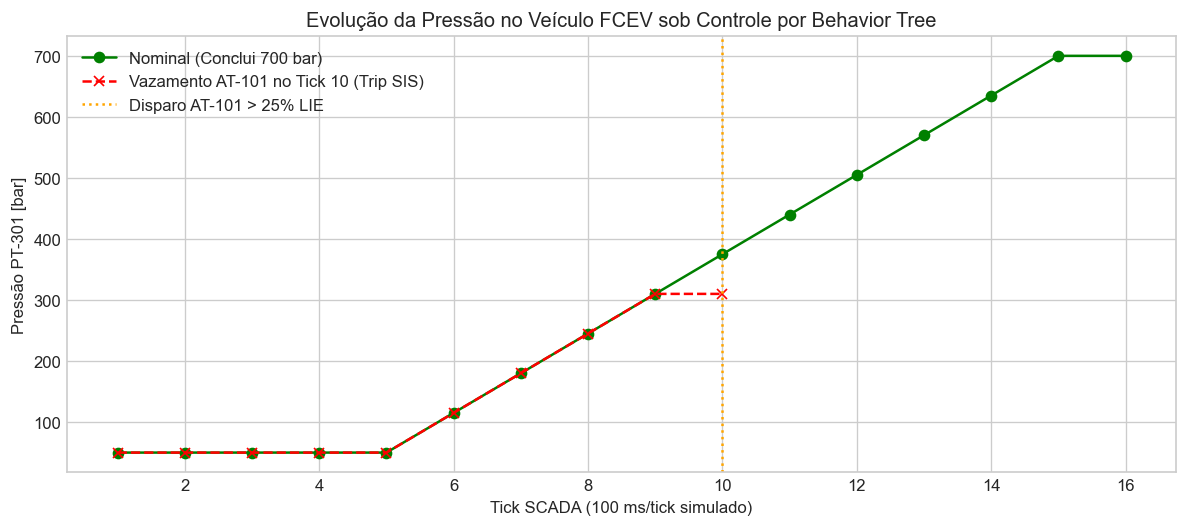

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(df_nom["Tick"], df_nom["PT_301 (bar)"], marker="o", color="green", label="Nominal (Conclui 700 bar)")
ax.plot(df_vaz["Tick"], df_vaz["PT_301 (bar)"], marker="x", color="red", linestyle="--", label="Vazamento AT-101 no Tick 10 (Trip SIS)")
ax.axvline(10, color="orange", linestyle=":", label="Disparo AT-101 > 25% LIE")
ax.set_title("Evolução da Pressão no Veículo FCEV sob Controle por Behavior Tree")
ax.set_xlabel("Tick SCADA (100 ms/tick simulado)")
ax.set_ylabel("Pressão PT-301 [bar]")
ax.legend()
plt.tight_layout()
plt.show()